------- 전체 물동량 기술 통계량 -------  
count    414024.00
mean        536.60
std         834.54
min           0.00
25%         105.00
50%         287.00
75%         671.00
max       42921.00
Name: 물동량, dtype: str


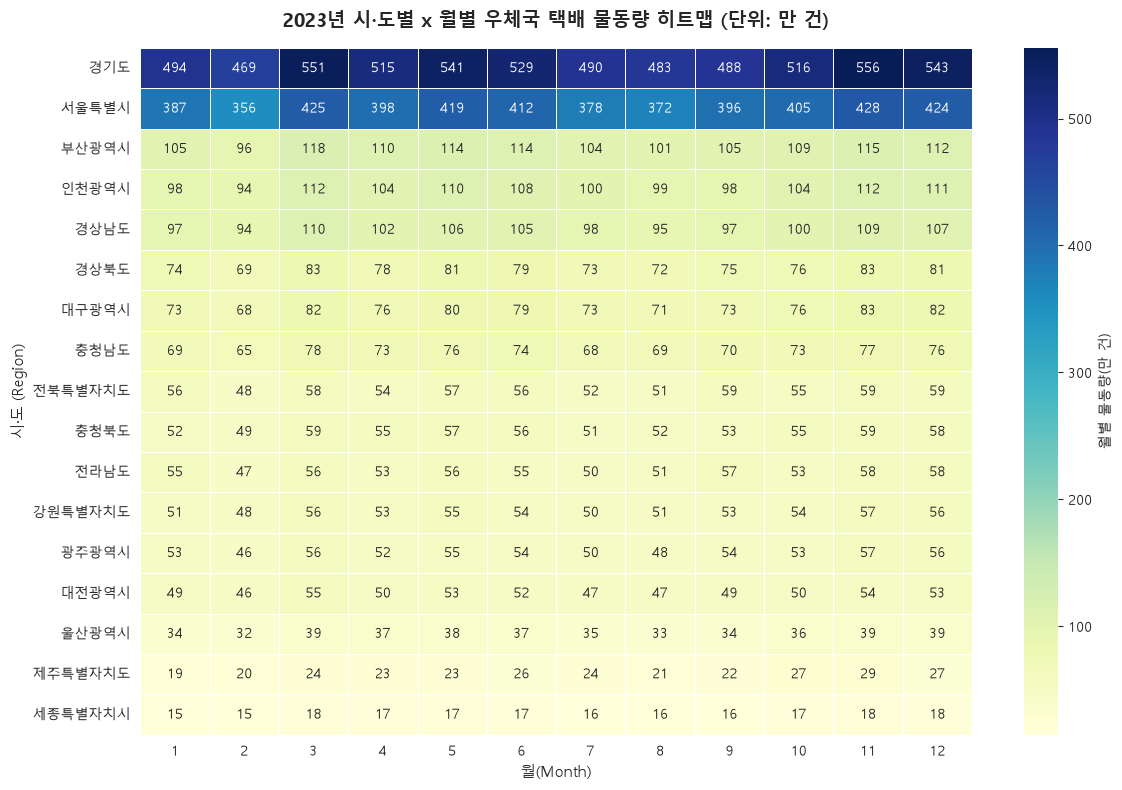

In [1]:
import matplotlib.pyplot as plt  
import pandas as pd  
import seaborn as sns  

sns.set_style('whitegrid')
plt.rc('font', family = 'Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = (False) # 그래프 축에서 마이너스 (-) 기호 깨짐 방지함.

# 전처리한 데이터 불러오기
# 우편번호 5자리 앞 '0'이 사라지지 않게 문자열로 저장
data = pd.read_csv('preprocessed_parcel_data.csv', encoding='utf-8', dtype={'우편번호 5자리' : str})

# 주요 변수 기술 통계량 출력
print('------- 전체 물동량 기술 통계량 -------  ')
print(data['물동량'].describe().apply(lambda x: f'{x:.2f}'))

# 히트맵 생성 (시도 별 x 월별 물동량)
# 행 -> 시도, 열 -> 월 숫자로 해서 월별 총 물동량을 집계한 피벗 테이블 생성
pivot_sido_month = (data.pivot_table(index = '시도', columns='월 숫자', values='물동량', aggfunc='sum')/10000)

# 연간 총 물동량이 많은 시/도를 위에서 아래로 정렬함 (내림차순)
pivot_sido_month = pivot_sido_month.loc[pivot_sido_month.sum(axis=1).sort_values(ascending=False).index]

plt.figure(figsize=(12,8))

# 히트맵 시각화 (시/도 x 월별 물동량)
sns.heatmap(pivot_sido_month, annot = True, fmt = '.0f', cmap = 'YlGnBu', 
           linewidths = 0.5, cbar_kws={'label':'월별 물동량(만 건)'})

plt.title('2023년 시·도별 x 월별 우체국 택배 물동량 히트맵 (단위: 만 건)',
          fontsize = 14, fontweight = 'bold', pad = 15)

plt.xlabel('월(Month)' , fontsize = 11)
plt.ylabel('시·도 (Region)', fontsize=11)
plt.tight_layout()
plt.savefig('sido_month_heatmap.png', dpi = 300)
plt.show()
